# Task 4: Numerical Feature Scaling

**Objective:** Compare Min-Max Scaling, StandardScaler, RobustScaler, and Yeo-Johnson Power Transformation. Compare their distribution effects and Ridge Regression performance.

**Input:** `data/processed/womens_clothing_final.csv`  
**Outputs:** `data/processed/womens_clothing_scaled.csv`, reports in `reports/`.

`units_sold` is the default regression target. Change `TARGET_COLUMN` if needed. Binary indicators and ID columns are excluded from scaling.

## 1. Import libraries

In [1]:
import logging
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate


## 2. Load Task 3 output

In [2]:
current_path = Path.cwd()
PROJECT_ROOT = next(
    (p for p in [current_path, *current_path.parents]
     if (p / "data" / "processed" / "womens_clothing_final.csv").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the main Womens_Clothing_ML_Project folder in VS Code.")
INPUT_PATH = PROJECT_ROOT / "data" / "processed" / "womens_clothing_final.csv"
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed"
REPORT_PATH = PROJECT_ROOT / "reports"
LOG_PATH = PROJECT_ROOT / "logs"
for folder in [OUTPUT_PATH, REPORT_PATH, LOG_PATH]:
    folder.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(INPUT_PATH)
print("Dataset shape:", df.shape)
display(df.head())

logging.basicConfig(
    filename=LOG_PATH / "task_4.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    force=True
)


Dataset shape: (1539, 40)


,title,title_orig,price,retail_price,currency_buyer,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,...,merchant_name,merchant_info_subtitle,merchant_rating_count,merchant_rating,merchant_id,merchant_has_profile_picture,merchant_profile_picture,product_url,product_picture,product_id
0,2020 Summer Vintage Flamingo Print Pajamas Se...,2020 Summer Vintage Flamingo Print Pajamas Se...,16.00,14.0,EUR,100,False,3.76,54.0,26.0,...,zgrdejia,(568 notes),568.0,4.128521,595097d6a26f6e070cb878d1,False,NaN,https://www.wish.com/c/5e9ae51d43d6a96e303acdb0,https://contestimg.wish.com/api/webimage/5e9ae...,5e9ae51d43d6a96e303acdb0
1,SSHOUSE Summer Casual Sleeveless Soirée Party ...,Women's Casual Summer Sleeveless Sexy Mini Dress,8.00,22.0,EUR,12350,True,3.45,2143.5,1058.0,...,sarahouse,"83 % avis positifs (17,752 notes)",17752.0,3.899673,56458aa03a698c35c9050988,False,NaN,https://www.wish.com/c/58940d436a0d3d5da4e95a38,https://contestimg.wish.com/api/webimage/58940...,58940d436a0d3d5da4e95a38
2,2020 Nouvelle Arrivée Femmes Printemps et Été ...,2020 New Arrival Women Spring and Summer Beach...,8.00,43.0,EUR,100,False,3.57,14.0,5.0,...,hxt520,86 % avis positifs (295 notes),295.0,3.989831,5d464a1ffdf7bc44ee933c65,False,NaN,https://www.wish.com/c/5ea10e2c617580260d55310a,https://contestimg.wish.com/api/webimage/5ea10...,5ea10e2c617580260d55310a
3,Hot Summer Cool T-shirt pour les femmes Mode T...,Hot Summer Cool T Shirt for Women Fashion Tops...,8.00,8.0,EUR,5000,True,4.03,579.0,295.0,...,allenfan,"(23,832 notes)",23832.0,4.020435,58cfdefdacb37b556efdff7c,False,NaN,https://www.wish.com/c/5cedf17ad1d44c52c59e4aca,https://contestimg.wish.com/api/webimage/5cedf...,5cedf17ad1d44c52c59e4aca
4,Femmes Shorts d'été à lacets taille élastique ...,Women Summer Shorts Lace Up Elastic Waistband ...,2.72,3.0,EUR,100,True,3.10,20.0,6.0,...,happyhorses,"85 % avis positifs (14,482 notes)",14482.0,4.001588,5ab3b592c3911a095ad5dadb,False,NaN,https://www.wish.com/c/5ebf5819ebac372b070b0e70,https://contestimg.wish.com/api/webimage/5ebf5...,5ebf5819ebac372b070b0e70


## 3. Identify numerical features

In [3]:
TARGET_COLUMN = "units_sold"
if TARGET_COLUMN not in df.columns:
    raise ValueError(f"Target column '{TARGET_COLUMN}' not found.")

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
excluded_columns = [TARGET_COLUMN, "product_id", "merchant_id"]
binary_columns = [c for c in numeric_columns if df[c].nunique(dropna=True) <= 2]
feature_columns = [
    c for c in numeric_columns
    if c not in excluded_columns and c not in binary_columns
]
print("Target:", TARGET_COLUMN)
print("Features:", feature_columns)
print("Binary columns excluded:", binary_columns)
if not feature_columns:
    raise ValueError("No continuous numerical features available.")


Target: units_sold
Features: ['price', 'retail_price', 'rating', 'rating_count', 'rating_five_count', 'rating_four_count', 'rating_three_count', 'rating_two_count', 'rating_one_count', 'product_variation_inventory', 'shipping_option_price', 'countries_shipped_to', 'merchant_rating_count', 'merchant_rating']
Binary columns excluded: ['badges_count', 'inventory_total']


## 4. Handle missing and infinite values

In [4]:
X = df[feature_columns].replace([np.inf, -np.inf], np.nan)
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=feature_columns,
    index=df.index
)
print("Missing values after imputation:", X_imputed.isna().sum().sum())


Missing values after imputation: 0


## 5. Apply scaling techniques

In [5]:
scalers = {
    "MinMaxScaler": MinMaxScaler(),
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler(),
    "PowerTransformer": PowerTransformer(method="yeo-johnson", standardize=True)
}
scaled_datasets = {}
for name, scaler in scalers.items():
    try:
        values = scaler.fit_transform(X_imputed)
        scaled_datasets[name] = pd.DataFrame(values, columns=feature_columns, index=df.index)
        logging.info("%s applied successfully.", name)
    except Exception as error:
        logging.exception("%s failed: %s", name, error)
        print(name, "failed:", error)
print("Successfully tested:", list(scaled_datasets))


Successfully tested: ['MinMaxScaler', 'StandardScaler', 'RobustScaler', 'PowerTransformer']


## 6. Compare statistical properties

In [6]:
rows = []
for name, scaled_df in scaled_datasets.items():
    for col in feature_columns:
        rows.append({
            "Scaling_Technique": name,
            "Feature": col,
            "Mean": scaled_df[col].mean(),
            "Standard_Deviation": scaled_df[col].std(),
            "Minimum": scaled_df[col].min(),
            "Maximum": scaled_df[col].max(),
            "Skewness": scaled_df[col].skew()
        })
scaling_report = pd.DataFrame(rows)
display(scaling_report.head(20))
scaling_report.to_csv(REPORT_PATH / "task_4_scaling_statistics.csv", index=False)


,Scaling_Technique,Feature,Mean,Standard_Deviation,Minimum,Maximum,Skewness
0,MinMaxScaler,price,4.113209e-01,0.208363,0.000000,1.000000,0.476996
1,MinMaxScaler,retail_price,3.327261e-01,0.329044,0.000000,1.000000,1.176128
2,MinMaxScaler,rating,7.057099e-01,0.127155,0.000000,1.000000,-0.547370
3,MinMaxScaler,rating_count,2.660465e-01,0.346301,0.000000,1.000000,1.213989
4,MinMaxScaler,rating_five_count,2.609635e-01,0.341559,0.000000,1.000000,1.261699
5,MinMaxScaler,rating_four_count,2.641124e-01,0.344507,0.000000,1.000000,1.240773
6,MinMaxScaler,rating_three_count,2.569564e-01,0.337854,0.000000,1.000000,1.281772
7,MinMaxScaler,rating_two_count,2.535934e-01,0.333463,0.000000,1.000000,1.288831
8,MinMaxScaler,rating_one_count,2.608528e-01,0.334758,0.000000,1.000000,1.265436
9,MinMaxScaler,product_variation_inventory,6.601557e-01,0.433598,0.000000,1.000000,-0.590107


## 7. Visualize original and scaled distributions

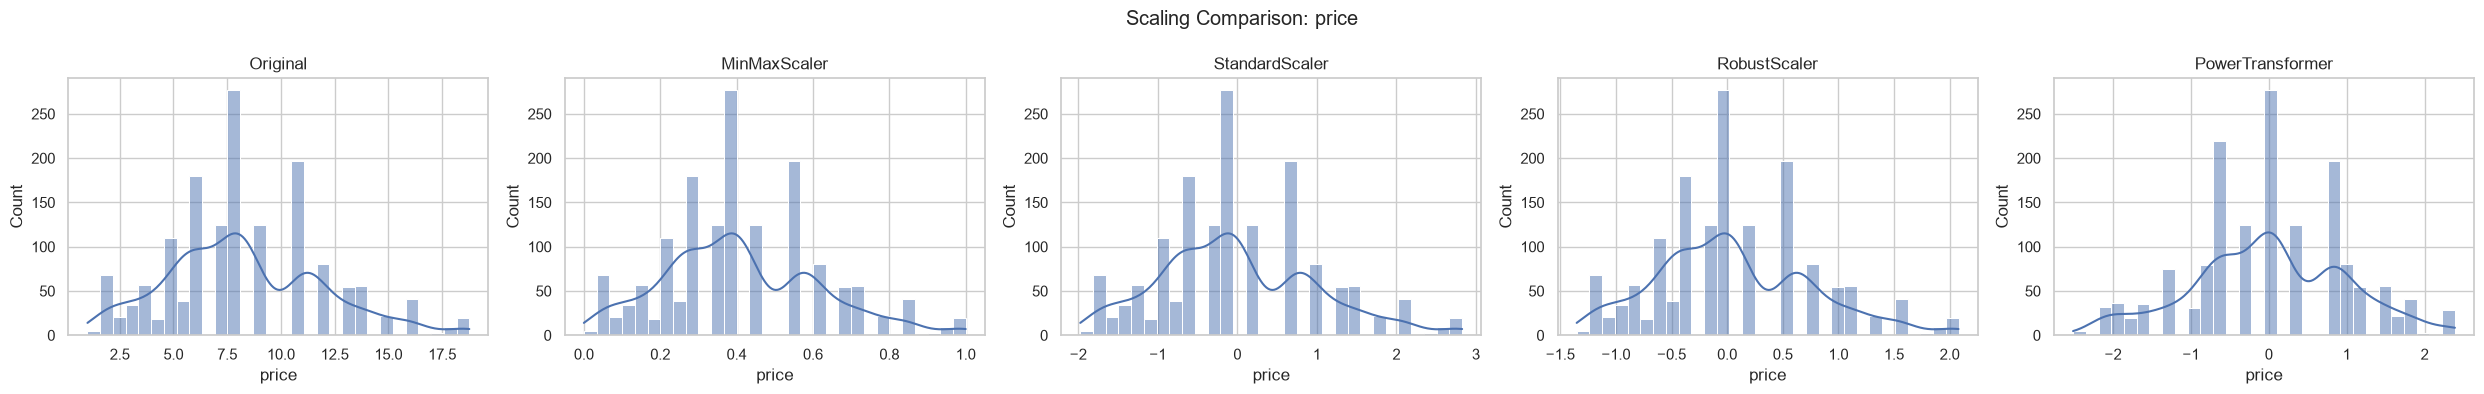

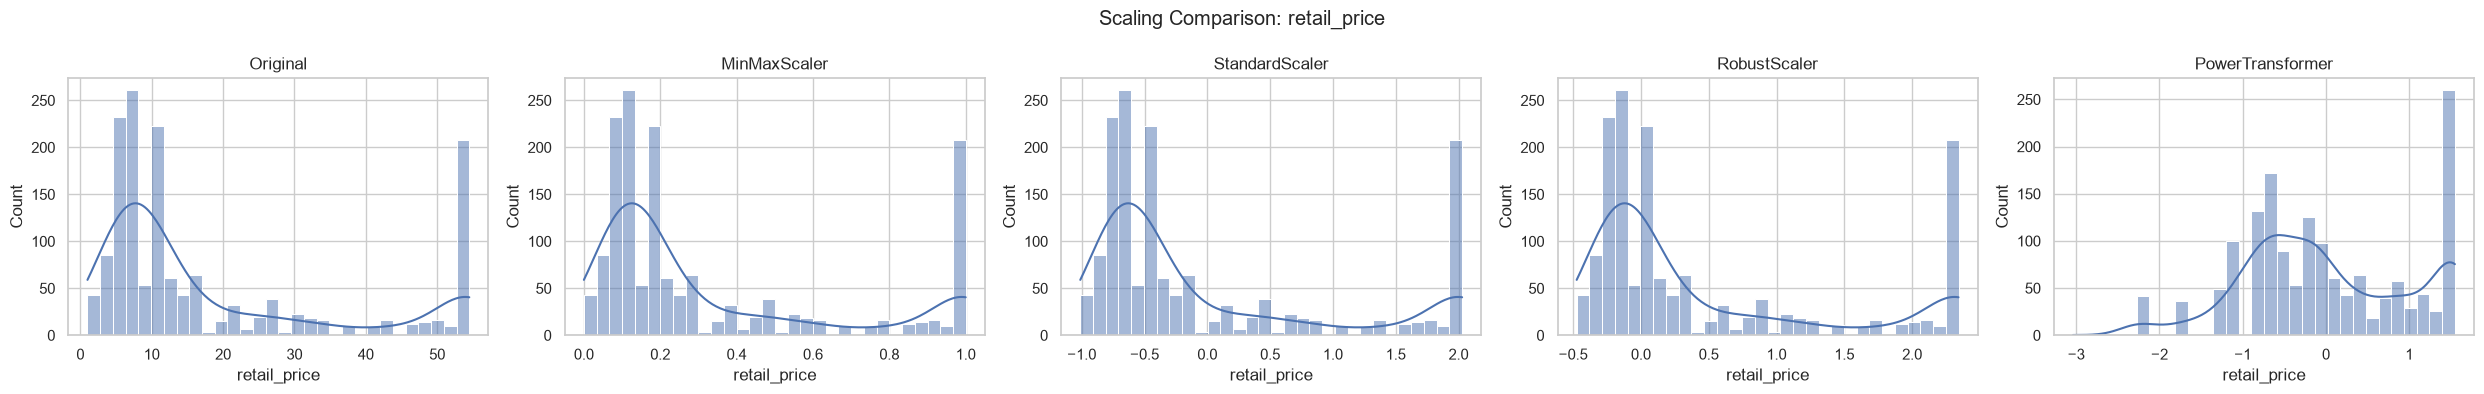

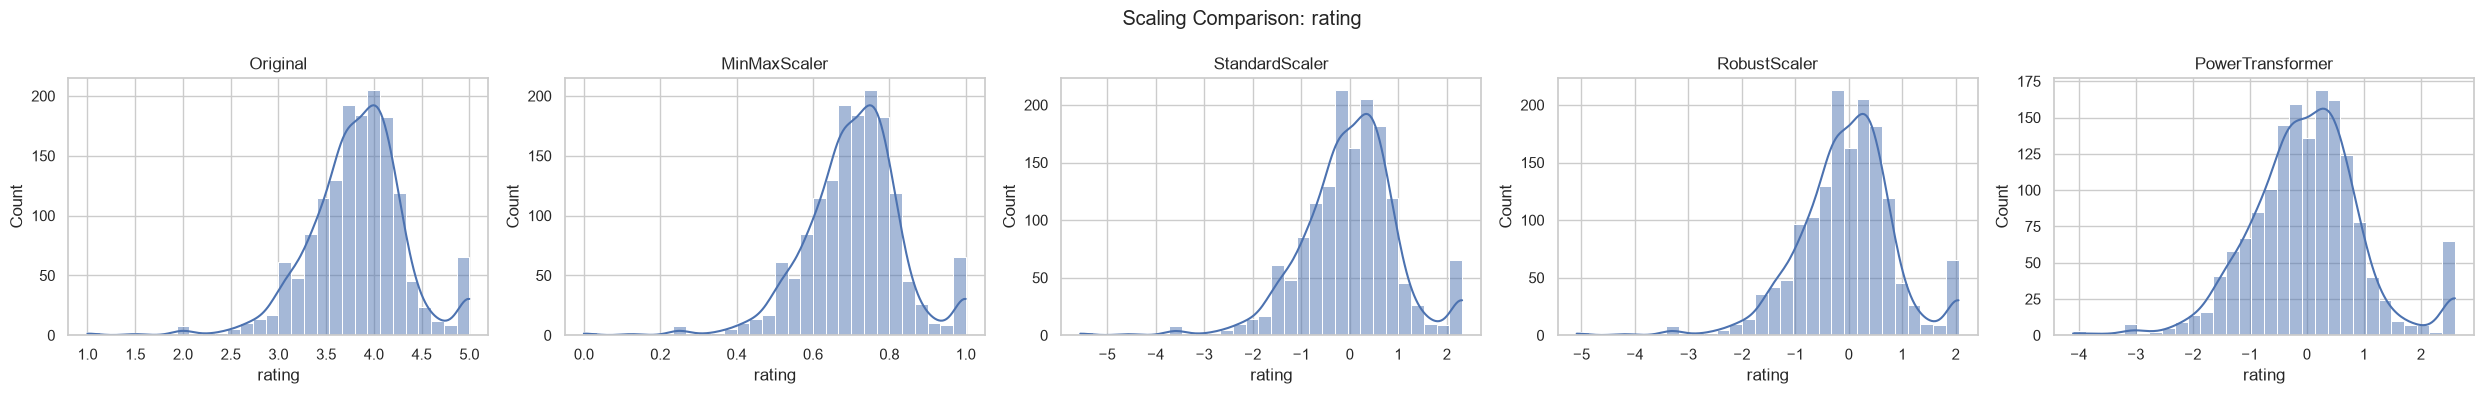

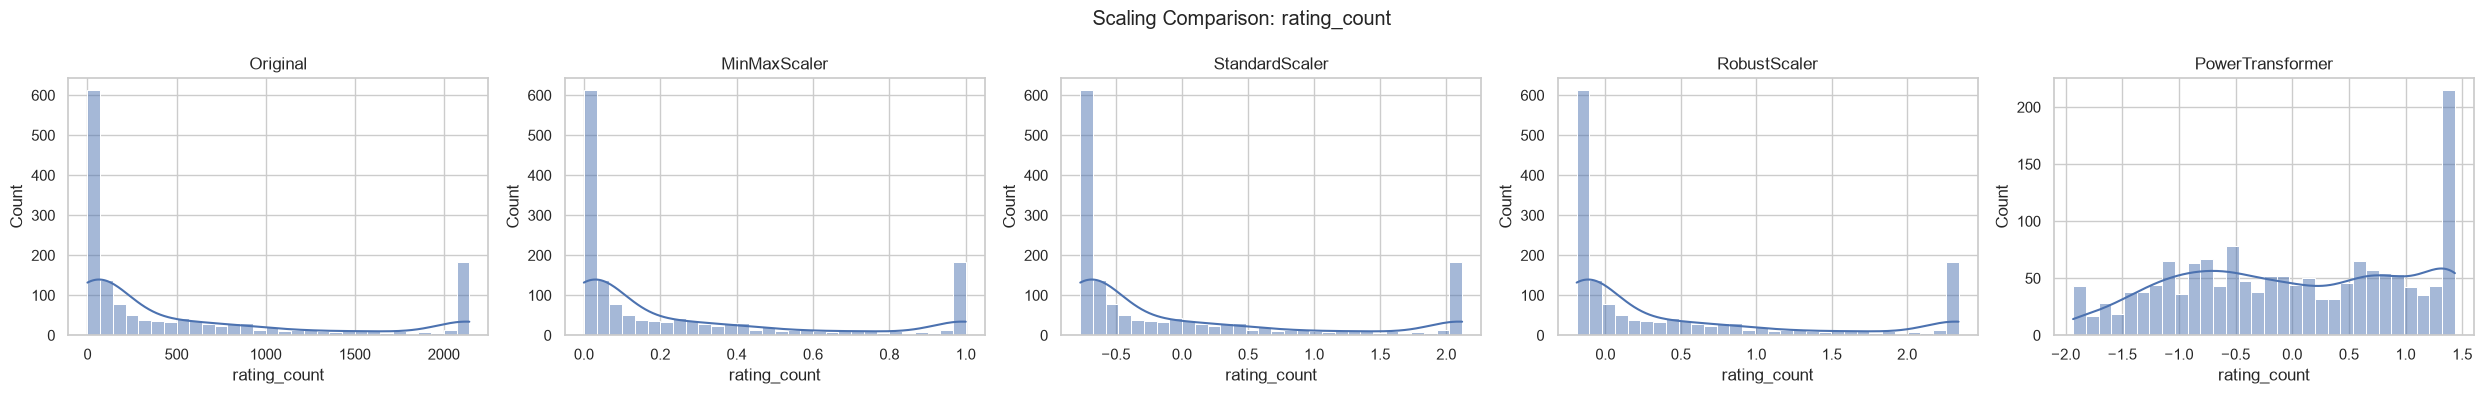

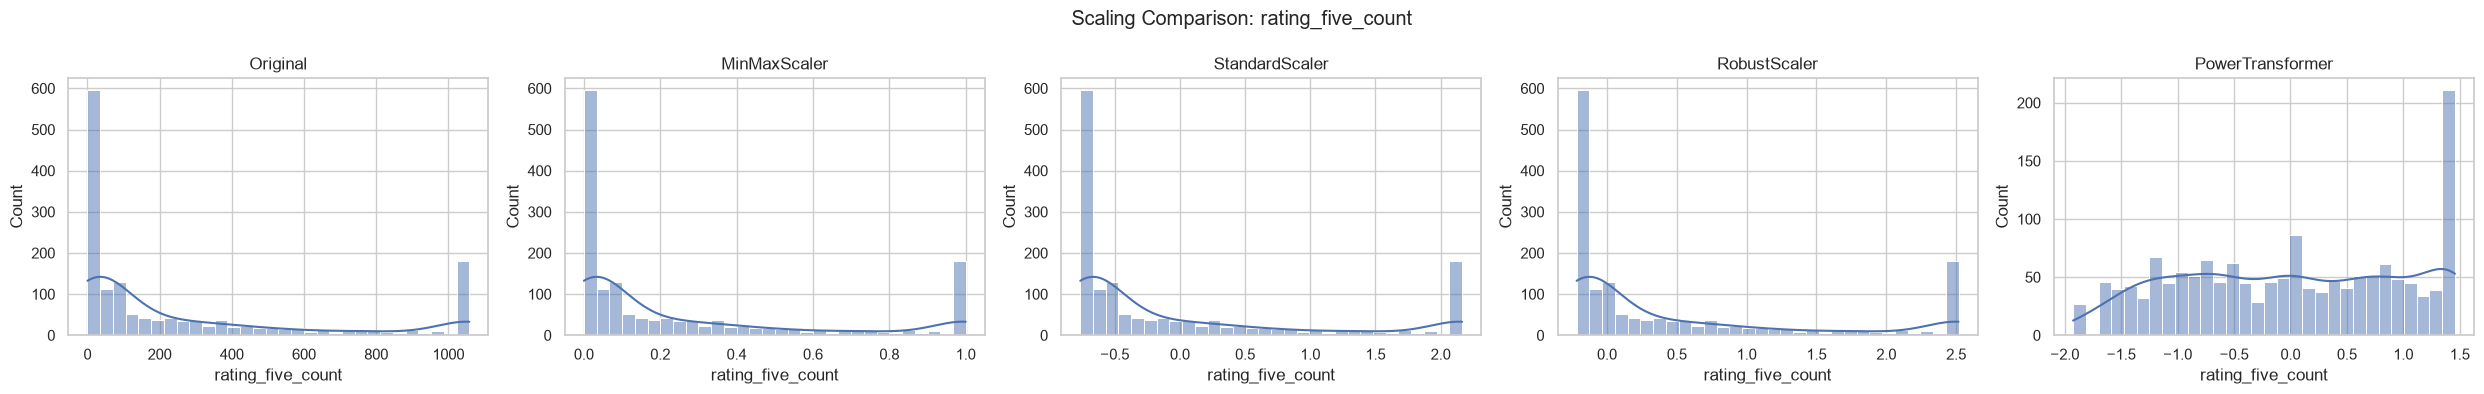

In [7]:
def compare_distributions(feature):
    techniques = list(scaled_datasets)
    fig, axes = plt.subplots(1, len(techniques) + 1, figsize=(5 * (len(techniques) + 1), 4))
    sns.histplot(X_imputed[feature], bins=30, kde=True, ax=axes[0])
    axes[0].set_title("Original")
    for i, name in enumerate(techniques, start=1):
        sns.histplot(scaled_datasets[name][feature], bins=30, kde=True, ax=axes[i])
        axes[i].set_title(name)
    fig.suptitle(f"Scaling Comparison: {feature}")
    plt.tight_layout()
    plt.show()

for col in feature_columns[:5]:
    compare_distributions(col)


## 8. Compare Ridge Regression using cross-validation

Preprocessing is fitted within each fold to avoid leakage during model comparison.

In [8]:
y = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
valid = y.notna() & np.isfinite(y)
X_model = df.loc[valid, feature_columns].replace([np.inf, -np.inf], np.nan)
y_model = y.loc[valid]
if len(X_model) < 10 or y_model.nunique() < 2:
    raise ValueError("Not enough valid data or target variation for cross-validation.")

cv = KFold(n_splits=min(5, len(X_model)), shuffle=True, random_state=42)
model_rows = []
for name, scaler in scalers.items():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scaler),
        ("model", Ridge())
    ])
    try:
        scores = cross_validate(
            pipeline, X_model, y_model, cv=cv,
            scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"},
            error_score="raise"
        )
        model_rows.append({
            "Scaling_Technique": name,
            "Mean_R2": scores["test_r2"].mean(),
            "Mean_RMSE": -scores["test_rmse"].mean()
        })
    except Exception as error:
        logging.exception("Evaluation failed for %s: %s", name, error)
        print(name, "evaluation failed:", error)

model_comparison = pd.DataFrame(model_rows)
if model_comparison.empty:
    raise ValueError("No scaler completed model evaluation.")
model_comparison = model_comparison.sort_values(
    ["Mean_RMSE", "Mean_R2"], ascending=[True, False]
).reset_index(drop=True)
display(model_comparison)
model_comparison.to_csv(REPORT_PATH / "task_4_scaling_comparison.csv", index=False)


,Scaling_Technique,Mean_R2,Mean_RMSE
0,RobustScaler,0.881483,1435.669952
1,StandardScaler,0.881475,1435.697151
2,MinMaxScaler,0.881016,1438.853322
3,PowerTransformer,0.697309,2306.824573


## 9. Select the best technique and save dataset

In [9]:
best_scaler_name = model_comparison.iloc[0]["Scaling_Technique"]
print("Selected scaling technique:", best_scaler_name)

final_df = df.copy()
for col in feature_columns:
    final_df[col] = scaled_datasets[best_scaler_name][col]

OUTPUT_FILE = OUTPUT_PATH / "womens_clothing_scaled.csv"
final_df.to_csv(OUTPUT_FILE, index=False)
logging.info("Selected %s. Saved %s", best_scaler_name, OUTPUT_FILE)
print("Saved:", OUTPUT_FILE)


Selected scaling technique: RobustScaler
Saved: d:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project\data\processed\womens_clothing_scaled.csv


## 10. Final summary

In [10]:
print("TASK 4 COMPLETED")
print("Rows and columns:", df.shape)
print("Selected technique:", best_scaler_name)
print("Features scaled:", len(feature_columns))
print("Target left unchanged:", TARGET_COLUMN)
print("Output:", OUTPUT_FILE)


TASK 4 COMPLETED
Rows and columns: (1539, 40)
Selected technique: RobustScaler
Features scaled: 14
Target left unchanged: units_sold
Output: d:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project\data\processed\womens_clothing_scaled.csv


## Interpretation

- **MinMaxScaler:** maps values to a fixed range, usually 0–1.
- **StandardScaler:** centers features and scales to unit variance.
- **RobustScaler:** uses median and interquartile range, reducing sensitivity to extreme values.
- **PowerTransformer:** applies a power transformation to make distributions more Gaussian-like.

The selected scaler is best only for this Ridge Regression comparison and dataset. Reassess for other models. The saved full-data CSV is exploratory; for predictive modelling, fit preprocessing on training data only.